<a href="https://colab.research.google.com/github/willismax/MediaSystem-Python-Course/blob/main/course-115-v2/colab/W04_Diffusion_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06｜擴散模型如何學會去噪：動手實驗

對應講義：[06 擴散模型如何學習去噪（W04）](https://hackmd.io/@wiimax/HknntqYIGe)

這份筆記本把講義的觀念變成可以親手操作的實驗。不需要修改程式也能跑完；
每個實驗後面都有 ✍️ 的地方，請把你的預測與觀察寫下來。

| 段落 | 內容 | 需要 GPU？ |
| --- | --- | --- |
| 實驗一 | 親手把圖片逐漸變成雜訊（Forward Diffusion） | 不需要 |
| 實驗二 | 從純雜訊生成圖片（預訓練 DDPM） | 建議 |
| 實驗三 | 控制變因：只改 Seed／只改步數 | 建議 |
| 挑戰 | 拆開 Pipeline，看每一步的中間結果 | 建議 |

**開始前**：上方選單「執行階段 → 變更執行階段類型」選 **T4 GPU**，再按「全部執行」。

## 0｜環境準備

In [1]:
!pip uninstall -y -q torchao

In [2]:
!pip install -q -U diffusers accelerate

In [3]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print("使用裝置：", device)
if device == "cpu":
    print("⚠️ 沒有偵測到 GPU：實驗一可以照常執行，實驗二之後會非常慢。")
    print("   請到「執行階段 → 變更執行階段類型」選擇 T4 GPU。")

使用裝置： cuda


---
## 實驗一｜親手把圖片逐漸變成雜訊

這個實驗**不需要 AI 模型**。我們直接用講義的前向加噪公式：

$$x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1-\bar{\alpha}_t}\,\epsilon$$

- $x_0$：原圖（先縮放到 -1 ~ 1）
- $\epsilon$：隨機高斯雜訊
- $\bar{\alpha}_t$：還保留多少原圖訊號（接近 1 = 幾乎是原圖，接近 0 = 幾乎是雜訊）

### 1-1 準備圖片
預設使用內建範例圖。想用自己的照片，把 `USE_MY_IMAGE` 改成 `True` 再執行。

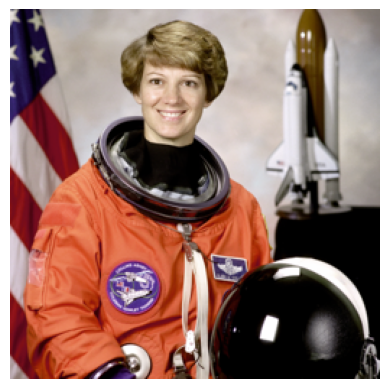

In [4]:
from skimage import data

USE_MY_IMAGE = False   # 改成 True 可以上傳自己的照片

if USE_MY_IMAGE:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    img = Image.open(filename).convert("RGB")
else:
    img = Image.fromarray(data.astronaut())

img = img.resize((256, 256))
plt.imshow(img)
plt.axis("off")
plt.show()

### 1-2 用五個不同的 ᾱ 加噪

注意 `noise` 只產生**一次**，五張圖共用同一份雜訊，這樣差異才只來自 ᾱ。

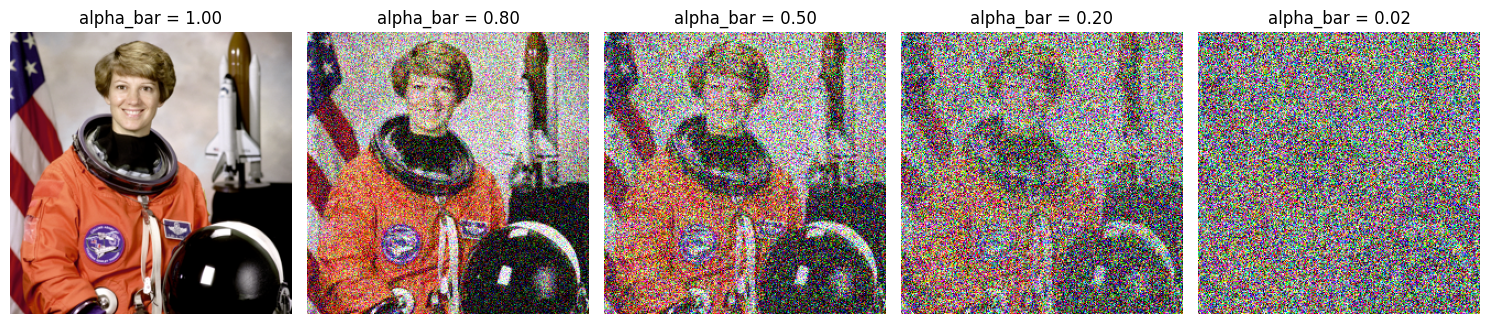

In [5]:
# 0~255 → -1~1
x0 = np.asarray(img).astype(np.float32) / 127.5 - 1.0

# 固定 Seed，只產生一份雜訊
rng = np.random.default_rng(42)
noise = rng.standard_normal(x0.shape).astype(np.float32)


def add_noise(x0, noise, alpha_bar):
    """前向加噪公式：一部分原圖 + 一部分雜訊"""
    return np.sqrt(alpha_bar) * x0 + np.sqrt(1 - alpha_bar) * noise


def to_image(x):
    """-1~1 → 0~255，方便顯示"""
    return ((np.clip(x, -1, 1) + 1) * 127.5).astype(np.uint8)


alpha_bars = [1.00, 0.80, 0.50, 0.20, 0.02]

fig, axes = plt.subplots(1, len(alpha_bars), figsize=(3 * len(alpha_bars), 3.4))
for ax, ab in zip(axes, alpha_bars):
    ax.imshow(to_image(add_noise(x0, noise, ab)))
    ax.set_title(f"alpha_bar = {ab:.2f}")
    ax.axis("off")
plt.tight_layout()
plt.show()

✍️ **觀察紀錄**（雙擊這格就能編輯）

| ᾱ | 原圖訊號 | 雜訊 | 還認得出原圖嗎？ |
| --- | --- | --- | --- |
| 1.00 | 很多 | 幾乎沒有 | |
| 0.80 | | | |
| 0.50 | | | |
| 0.20 | | | |
| 0.02 | 很少 | 很多 | |

**問題**：從哪個 ᾱ 開始難以辨認原始物件？

### 1-3 真正的 Noise Schedule 長什麼樣子？

上面的 ᾱ 是我們手動挑的。經典 DDPM 實際上用 **1000 個 Timesteps**，
每一步的 β（加多少雜訊）從 0.0001 線性增加到 0.02，ᾱₜ 就是一路累乘下來的結果。

這格把 **Timestep t** 和 **ᾱₜ** 連起來看。

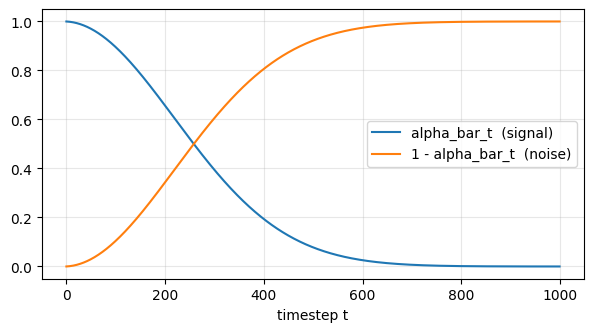

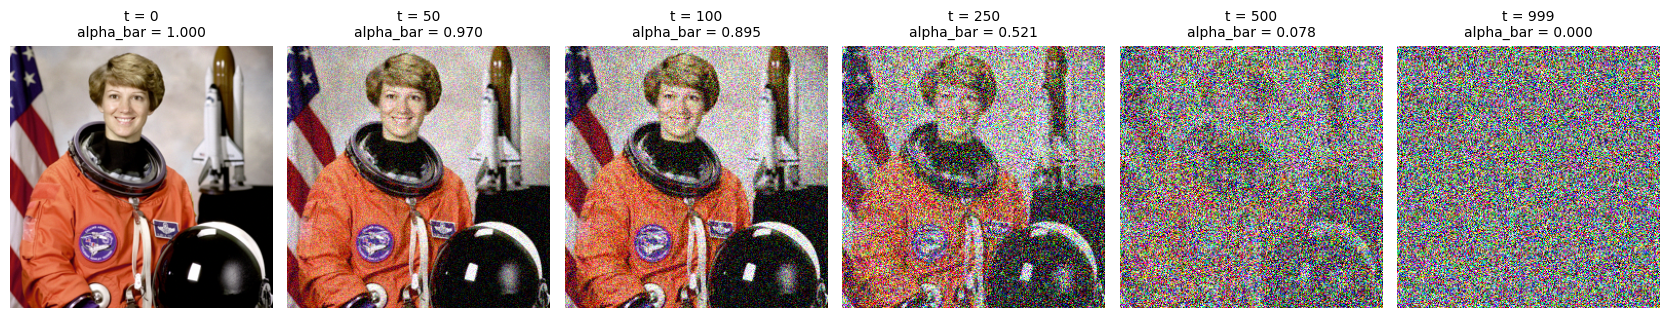

In [6]:
T = 1000
betas = np.linspace(1e-4, 0.02, T)          # DDPM 原始論文的 linear schedule
alphas_cumprod = np.cumprod(1 - betas)      # 這就是 ᾱₜ

plt.figure(figsize=(7, 3.5))
plt.plot(alphas_cumprod, label="alpha_bar_t  (signal)")
plt.plot(1 - alphas_cumprod, label="1 - alpha_bar_t  (noise)")
plt.xlabel("timestep t")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

ts = [0, 50, 100, 250, 500, 999]
fig, axes = plt.subplots(1, len(ts), figsize=(2.8 * len(ts), 3.4))
for ax, t in zip(axes, ts):
    ab = alphas_cumprod[t]
    ax.imshow(to_image(add_noise(x0, noise, ab)))
    ax.set_title(f"t = {t}\nalpha_bar = {ab:.3f}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

✍️ **想一想**：t = 250 時，原圖大概還剩多少比例？t = 999 時呢？
這說明了為什麼模型**一定要知道現在是第幾個 Timestep**。

### 1-4 如果每張都用不同的雜訊，還能公平比較嗎？

上排：五張共用同一份雜訊（剛剛的做法）。
下排：每張都重新產生一份新雜訊。

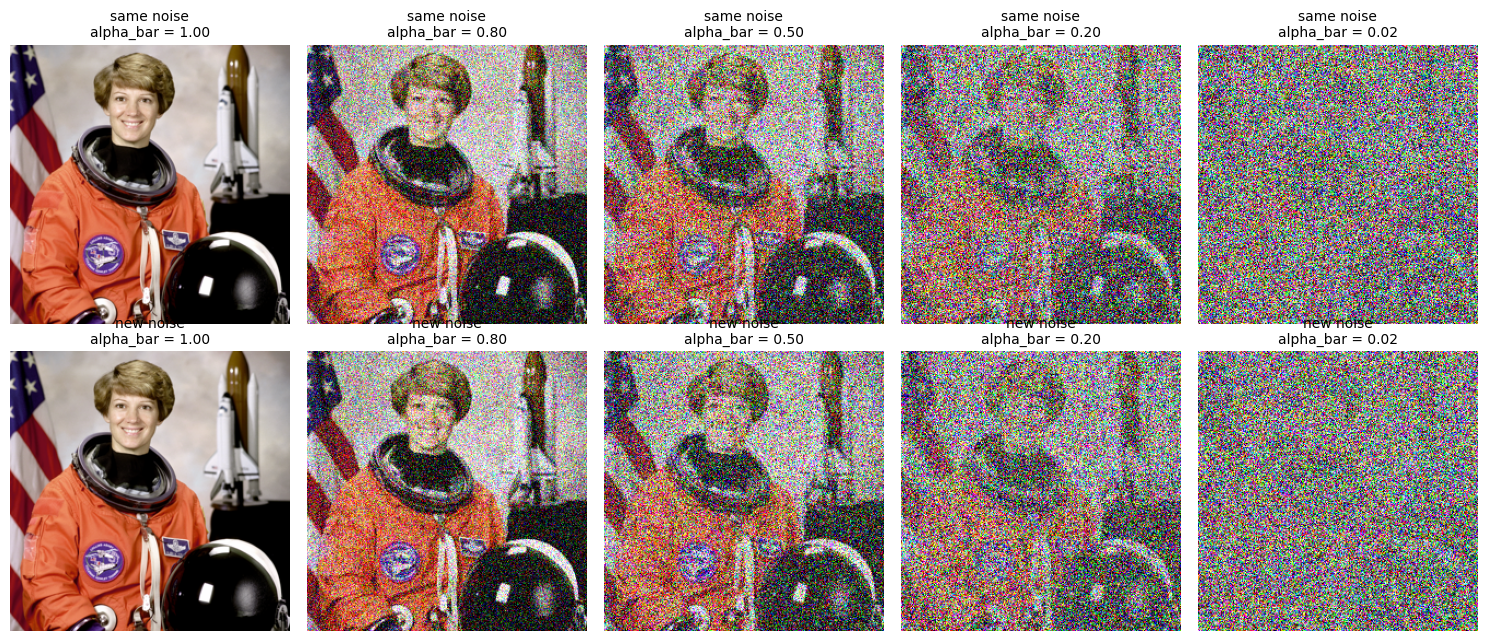

In [7]:
fig, axes = plt.subplots(2, len(alpha_bars), figsize=(3 * len(alpha_bars), 6.4))
for i, ab in enumerate(alpha_bars):
    new_noise = rng.standard_normal(x0.shape).astype(np.float32)
    axes[0, i].imshow(to_image(add_noise(x0, noise, ab)))
    axes[1, i].imshow(to_image(add_noise(x0, new_noise, ab)))
    axes[0, i].set_title(f"same noise\nalpha_bar = {ab:.2f}", fontsize=10)
    axes[1, i].set_title(f"new noise\nalpha_bar = {ab:.2f}", fontsize=10)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

✍️ 兩排**看起來**可能差不多，但如果你要比較「ᾱ 的影響」，哪一排的實驗設計比較嚴謹？為什麼？

---
## 實驗二｜從純雜訊生成圖片

使用 Hugging Face 上的 `google/ddpm-cifar10-32`：

- 32×32 的小圖、**沒有 Prompt**（Unconditional）
- Pipeline 只有兩個角色：**Model**（`UNet2DModel`）和 **Scheduler**（`DDPMScheduler`）

解析度低、沒有文字條件反而是優點，讓我們只專注在「雜訊 → 去噪 → 圖片」。

### 2-1 載入模型

In [8]:
from diffusers import DDPMPipeline

model_id = "google/ddpm-cifar10-32"
pipe = DDPMPipeline.from_pretrained(model_id).to(device)

print("Model     :", type(pipe.unet).__name__)
print("Scheduler :", type(pipe.scheduler).__name__)
print("訓練時的 Timesteps 數量：", pipe.scheduler.config.num_train_timesteps)

model_index.json:   0%|          | 0.00/180 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

Model     : UNet2DModel
Scheduler : DDPMScheduler
訓練時的 Timesteps 數量： 1000


### 2-2 準備一個顯示圖片的小工具

In [9]:
def show_images(images, titles=None, size=2.6):
    """把多張圖片排成一列；用 nearest 放大，保留 32×32 的像素感"""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(size * n, size + 0.5))
    axes = np.atleast_1d(axes)
    for i, ax in enumerate(axes):
        ax.imshow(images[i], interpolation="nearest")
        if titles:
            ax.set_title(titles[i], fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### 2-3 第一張生成圖

注意 `pipe()` **沒有輸入任何原始圖片**，它從隨機雜訊出發。

  0%|          | 0/1000 [00:00<?, ?it/s]

生成時間：23.5 秒


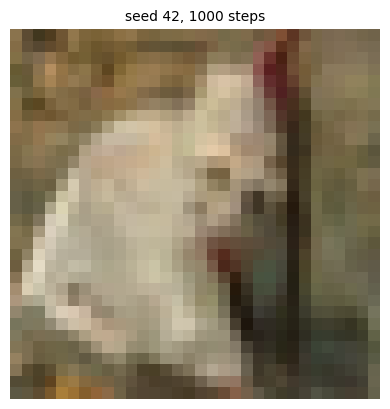

In [10]:
generator = torch.Generator(device=device).manual_seed(42)

start = time.time()
image = pipe(generator=generator, num_inference_steps=1000).images[0]
print(f"生成時間：{time.time() - start:.1f} 秒")

image.save("ddpm_seed42.png")
show_images([image], ["seed 42, 1000 steps"], size=4)

✍️ 這張圖看得出是什麼嗎？（CIFAR-10 的類別：飛機、汽車、鳥、貓、鹿、狗、青蛙、馬、船、卡車）

---
## 實驗三｜控制變因

> **想知道某個參數有什麼影響，就固定其他條件。**

### ✍️ 執行前先預測（這是「看 → 想 → 踹」的「想」）

1. 固定步數，只改 Seed：五張圖會**一樣**還是**不同**？
2. 固定 Seed，把步數從 1000 降到 10：會犧牲什麼？會省下什麼？
3. 只走 1 步，還看得出東西嗎？

寫下答案再往下執行。

我的預測：
1.
2.
3.

### 3-A 只改 Seed（固定模型、Scheduler、步數）

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

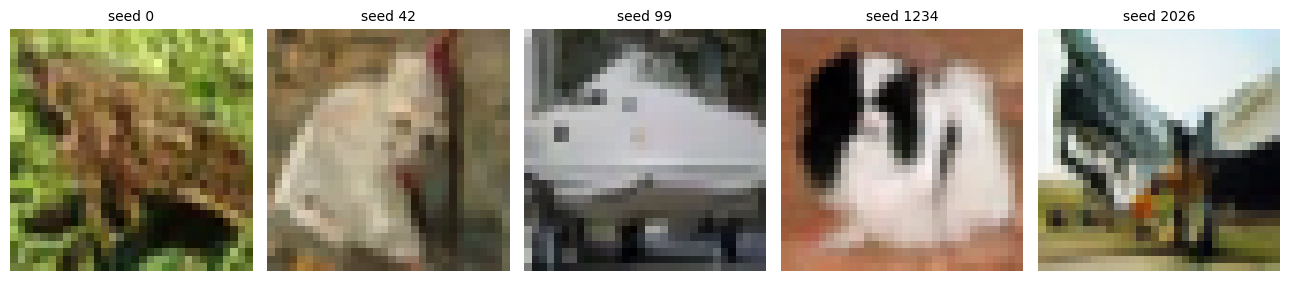

In [11]:
STEPS = 1000
seeds = [0, 42, 99, 1234, 2026]

images = []
for seed in seeds:
    generator = torch.Generator(device=device).manual_seed(seed)
    images.append(pipe(generator=generator, num_inference_steps=STEPS).images[0])

show_images(images, [f"seed {s}" for s in seeds])

再跑一次 `seed 42`，和上面那張比較：

  0%|          | 0/1000 [00:00<?, ?it/s]

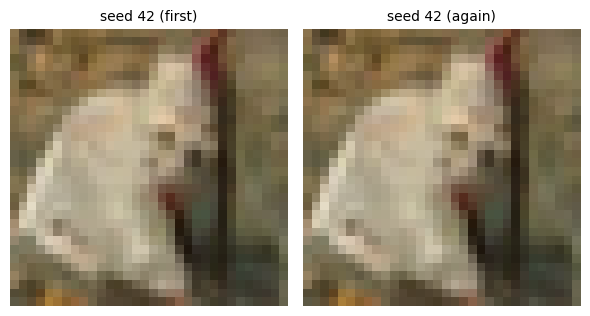

兩次結果完全相同： True


In [12]:
generator = torch.Generator(device=device).manual_seed(42)
again = pipe(generator=generator, num_inference_steps=STEPS).images[0]

same = np.array_equal(np.asarray(again), np.asarray(images[seeds.index(42)]))
show_images([images[seeds.index(42)], again], ["seed 42 (first)", "seed 42 (again)"], size=3)
print("兩次結果完全相同：", same)

✍️ Seed 改變的是**模型能力**、**圖片品質**，還是**生成的起點**？

> 小提醒：在 GPU 上，同一個 Seed 偶爾會因為運算順序出現極微小的數值差異，
> 但肉眼看起來應該一樣。

### 3-B 只改步數（固定模型、Scheduler、Seed）

這格同時記錄每組的執行時間。

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

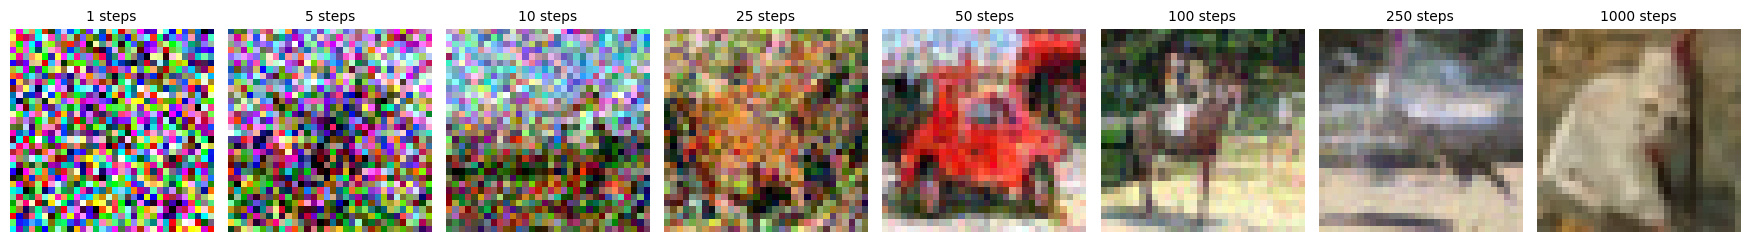

,Steps,Seed,時間（秒）
0,1,42,0.05
1,5,42,0.18
2,10,42,0.24
3,25,42,0.53
4,50,42,1.01
5,100,42,2.02
6,250,42,5.00
7,1000,42,21.15


In [13]:
import pandas as pd

step_list = [1, 5, 10, 25, 50, 100, 250, 1000]

images, titles, records = [], [], []
for steps in step_list:
    generator = torch.Generator(device=device).manual_seed(42)
    start = time.time()
    img_s = pipe(generator=generator, num_inference_steps=steps).images[0]
    elapsed = time.time() - start

    images.append(img_s)
    titles.append(f"{steps} steps")
    records.append({"Steps": steps, "Seed": 42, "時間（秒）": round(elapsed, 2)})

show_images(images, titles, size=2.2)
pd.DataFrame(records)

✍️ **觀察紀錄**

| Steps | 有可辨認的結構嗎？ | 觀察 |
| --- | --- | --- |
| 1 | | |
| 5 | | |
| 10 | | |
| 25 | | |
| 50 | | |
| 100 | | |
| 250 | | |
| 1000 | | |

**問題**：
1. 時間大致和步數成正比嗎？
2. 從 250 步到 1000 步，畫質改善的幅度和從 10 步到 50 步一樣大嗎？
3. 如果你要在網站上即時生成，你會選幾步？理由是什麼？

---
## 挑戰｜拆開 Pipeline：Model 與 Scheduler 各做什麼？

`pipe()` 把所有事情包起來了。這裡我們自己寫迴圈：

```
隨機雜訊 x_T
  ↓
Model：看 (x_t, t)，預測雜訊 ε̂
  ↓
Scheduler.step()：用 ε̂ 算出下一步 x_{t-1}
  ↓
重複，直到 x_0
```

每一步除了 `x_t`，Scheduler 還會順便給出「如果現在就停，模型猜的最終圖片」
（`pred_original_sample`）。兩排一起看，可以看到**結構是如何一步步長出來的**。

上排：目前的樣本 x_t


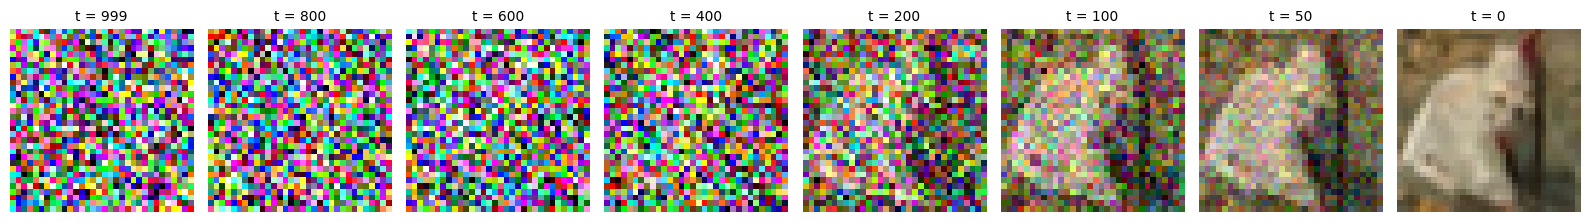

下排：模型此刻猜的最終圖片 pred_x0


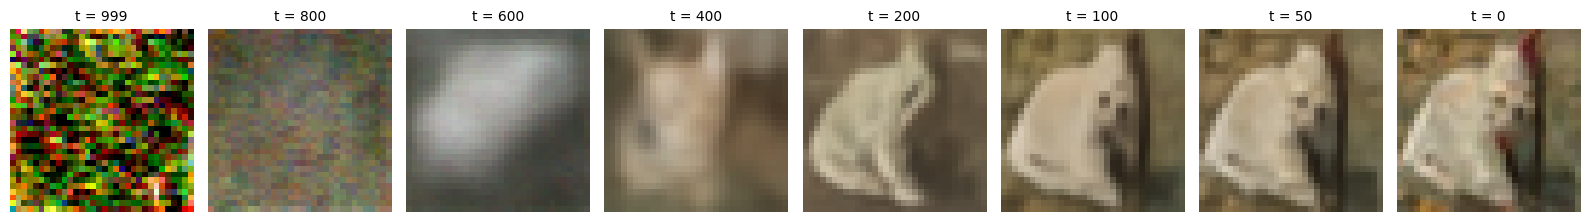

In [14]:
unet = pipe.unet
scheduler = pipe.scheduler
scheduler.set_timesteps(1000)

size = unet.config.sample_size
generator = torch.Generator(device=device).manual_seed(42)
x = torch.randn((1, 3, size, size), generator=generator, device=device)


def tensor_to_image(t):
    t = (t.clamp(-1, 1) + 1) / 2
    return t[0].permute(1, 2, 0).cpu().numpy()


snapshot_at = {999, 800, 600, 400, 200, 100, 50, 0}
xt_imgs, x0_imgs, labels = [], [], []

for t in scheduler.timesteps:
    with torch.no_grad():
        eps_pred = unet(x, t).sample                        # Model：預測雜訊
    out = scheduler.step(eps_pred, t, x, generator=generator)  # Scheduler：算下一步
    x = out.prev_sample

    if int(t) in snapshot_at:
        xt_imgs.append(tensor_to_image(x))
        x0_imgs.append(tensor_to_image(out.pred_original_sample))
        labels.append(f"t = {int(t)}")

print("上排：目前的樣本 x_t")
show_images(xt_imgs, labels, size=2)
print("下排：模型此刻猜的最終圖片 pred_x0")
show_images(x0_imgs, labels, size=2)

✍️ **挑戰問題**

1. 上排在 t = 999 到 t = 400 之間，肉眼看得到變化嗎？下排呢？
2. 大致的輪廓與顏色在哪個階段就決定了？細節又是在哪個階段補上的？
3. 這和講義說的「生成不是從雜訊底下找回原圖」有什麼關係？

---
## 總結

| 實驗 | 你親手驗證了什麼 |
| --- | --- |
| 實驗一 | 加噪不需要 AI；ᾱ 決定原圖與雜訊的比例；Timestep 對應不同雜訊程度 |
| 實驗二 | 生成從純雜訊開始，不需要輸入原圖 |
| 實驗三 | Seed 決定起點；步數影響品質與時間，但不是越多越好 |
| 挑戰 | Model 負責預測，Scheduler 負責走下一步；結構是逐步建立的 |

回到講義完成**檢核題**：<https://hackmd.io/@wiimax/HknntqYIGe>